# 07 – Modell C: Random Forest und XGBoost

Dieselben Daten und Variablen wie Modell B, aber statt eines Logits zwei **Baum-Modelle**. Modelle A und B bleiben unverändert.

- **Random Forest:** viele Entscheidungsbäume, jeder auf einer Zufallsauswahl von Zeilen und Variablen; die Vorhersage ist der Durchschnitt aller Bäume.
- **XGBoost:** Bäume werden nacheinander gebaut, jeder neue korrigiert die Fehler der bisherigen (Boosting).
- Beide **ohne Klassengewichte**, damit die Wahrscheinlichkeiten zur echten Basisrate passen (wie bei A und B).

Bäume können Nicht-Linearitäten und Wechselwirkungen selbst finden, die ein Logit nur sieht, wenn man sie vorgibt. Die Frage ist: Hilft diese Komplexität bei so wenigen Zielen?

## 1. Daten exakt wie Modell B

Gleicher Code wie Notebook 06: Modell-A-Datensatz aus 04 plus die neuen Kennzahlen, aufbereitet nur mit Trainingswerten; `roa`, `log_float` und `fcf_vol_missing` sind nach der Entscheidung vom 29.10. nicht dabei. Zur Kontrolle wird Modell B neu geschätzt; es muss dasselbe Pseudo-R² wie in 06 ergeben.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

DATA = Path("..") / "data" / "processed"
Y = "y_pe_main_h3"

data = pd.read_csv(DATA / "model_data_palepu.csv", dtype={"cik": str})
palepu_vars = ["roe", "sales_growth_1y", "liquidity", "leverage", "grdummy", "idummy",
               "log_assets", "float_to_book", "float_to_earnings"]
palepu_ind = sorted(c for c in data.columns if c.endswith("_missing"))

B_NEW = ["fcf_to_assets", "fcf_vol", "interest_coverage", "ppe_to_assets", "rd_to_assets", "cash_ratio", "altman_z2"]
data = data.merge(pd.read_csv(DATA / "firm_year_ratios.csv", usecols=["accession"] + B_NEW),
                  on="accession", how="left", validate="one_to_one")
train = data["split"] == "train"

# Regeln aus 04: Grenzen und Mediane nur aus dem Training; Indikator bei >2 % fehlend und >= 5 Positiven in der Lücke
lo, hi = data.loc[train, B_NEW].quantile(0.01), data.loc[train, B_NEW].quantile(0.99)
median = data.loc[train, B_NEW].clip(lo, hi, axis=1).median()
B_NEW_IND = []
for v in B_NEW:
    missing = data[v].isna()
    if missing[train].mean() > 0.02 and data.loc[train & missing, Y].sum() >= 5:
        data[f"{v}_missing"] = missing.astype(int)
        B_NEW_IND.append(f"{v}_missing")
    data[v] = data[v].clip(lo[v], hi[v]).fillna(median[v])
B_NEW_IND.remove("fcf_vol_missing")        # Entscheidung 29.10.: rho 0.714 zu einem Modell-A-Indikator

FEATURES = palepu_vars + B_NEW + palepu_ind + B_NEW_IND
assert len(FEATURES) == 25
tr = data[data["split"] == "train"].reset_index(drop=True)
te = data[data["split"] == "test"].reset_index(drop=True)

# Kontrolle: Modell B wie in 06
res_b = sm.Logit(tr[Y], sm.add_constant(tr[FEATURES])).fit(
    method="newton", maxiter=100, disp=False, cov_type="cluster", cov_kwds={"groups": tr["cik"]})
print(f"Modell B McFadden-R²: {res_b.prsquared:.2%} (Notebook 06: 4.55%)")
print(f"{len(FEATURES)} Variablen | Training {len(tr):,} Zeilen ({int(tr[Y].sum())} Positive) | Test {len(te):,} ({int(te[Y].sum())})")

Modell B McFadden-R²: 4.55% (Notebook 06: 4.55%)
25 Variablen | Training 18,058 Zeilen (167 Positive) | Test 9,596 (70)


## 2. Hyperparameter wählen – nur im Training, zeitlich validiert

Hyperparameter sind Einstellungen, die das Modell nicht selbst lernt (z. B. wie tief ein Baum werden darf). Gewählt wird so: **fitten auf FY2012–2015, bewerten auf FY2016–2017**, Kriterium **Log-Loss** (bestraft falsche *und* übertrieben sichere Wahrscheinlichkeiten; kleiner ist besser). Danach wird mit den gewählten Werten auf dem ganzen Training FY2012–2017 neu gefittet. Der Test wird dafür nicht angefasst.

**Grids (je 12 Kombinationen):**
- *Random Forest:* maximale Baumtiefe {4, 8, unbegrenzt} × minimale Blattgröße {20, 50, 100, 200}; fest: 500 Bäume, √(Anzahl Variablen) Variablen pro Teilung.
- *XGBoost:* maximale Baumtiefe {2, 3, 4} × Lernrate {0,03; 0,1} × Anzahl Bäume {200, 500}; fest: 80 % der Zeilen und Variablen pro Baum.

**Hinweis zur Validierung:** Das Label schaut 3 Jahre voraus. Ein Deal z. B. 2018 macht deshalb sowohl die FY2015-Zeile (Fit-Teil) als auch die FY2016/17-Zeilen derselben Firma (Validierung) positiv – die beiden Teile sind nicht ganz unabhängig.

In [2]:
fit_part = tr[tr["fiscal_year"] <= 2015]
val_part = tr[tr["fiscal_year"] >= 2016]
pos_fit = set(fit_part.loc[fit_part[Y] == 1, "cik"])
pos_val = set(val_part.loc[val_part[Y] == 1, "cik"])
print(f"Fit 2012-15: {len(fit_part):,} Zeilen, {int(fit_part[Y].sum())} Positive ({len(pos_fit)} Firmen)")
print(f"Validierung 2016-17: {len(val_part):,} Zeilen, {int(val_part[Y].sum())} Positive ({len(pos_val)} Firmen)")
print(f"Positive Firmen in beiden Teilen: {len(pos_fit & pos_val)} von {len(pos_val)}")

Fit 2012-15: 12,300 Zeilen, 99 Positive (51 Firmen)
Validierung 2016-17: 5,758 Zeilen, 68 Positive (43 Firmen)
Positive Firmen in beiden Teilen: 18 von 43


In [3]:
from itertools import product
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 20261030

def make_rf(max_depth, min_samples_leaf):
    return RandomForestClassifier(n_estimators=500, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                  max_features="sqrt", n_jobs=-1, random_state=SEED)   # keine class_weight

def make_xgb(max_depth, learning_rate, n_estimators):
    return XGBClassifier(max_depth=max_depth, learning_rate=learning_rate, n_estimators=n_estimators,
                         subsample=0.8, colsample_bytree=0.8, objective="binary:logistic",
                         eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=SEED)  # kein scale_pos_weight

def validate(make, grid_values, names):
    rows = []
    for values in product(*grid_values):
        model = make(*values).fit(fit_part[FEATURES], fit_part[Y])
        p = model.predict_proba(val_part[FEATURES])[:, 1]
        rows.append({**dict(zip(names, values)), "Log-Loss (Validierung)": log_loss(val_part[Y], p),
                     "ROC-AUC (Validierung, nur Info)": roc_auc_score(val_part[Y], p)})
    return pd.DataFrame(rows).sort_values("Log-Loss (Validierung)").reset_index(drop=True)

# Referenz: Log-Loss, wenn man allen Zeilen einfach die Basisrate des Fit-Teils vorhersagt
base_ll = log_loss(val_part[Y], np.full(len(val_part), fit_part[Y].mean()))
print(f"Referenz-Log-Loss (nur Basisrate): {base_ll:.5f}")

grid_rf = validate(make_rf, [[4, 8, None], [20, 50, 100, 200]], ["max_depth", "min_samples_leaf"])
grid_rf.round(5)

Referenz-Log-Loss (nur Basisrate): 0.06493


,max_depth,min_samples_leaf,Log-Loss (Validierung),"ROC-AUC (Validierung, nur Info)"
0,NaN,100,0.06304,0.65283
1,8.0,50,0.06308,0.65664
2,8.0,100,0.06309,0.65358
3,8.0,20,0.06316,0.65317
4,NaN,50,0.06317,0.65057
5,8.0,200,0.06327,0.64584
6,NaN,20,0.06331,0.64972
7,NaN,200,0.06331,0.64382
8,4.0,100,0.06371,0.63803
9,4.0,200,0.06373,0.63208


In [4]:
grid_xgb = validate(make_xgb, [[2, 3, 4], [0.03, 0.1], [200, 500]], ["max_depth", "learning_rate", "n_estimators"])
grid_xgb.round(5)

,max_depth,learning_rate,n_estimators,Log-Loss (Validierung),"ROC-AUC (Validierung, nur Info)"
0,2,0.03,200,0.06446,0.63759
1,3,0.03,200,0.06478,0.65021
2,4,0.03,200,0.06562,0.65779
3,2,0.03,500,0.06635,0.64425
4,3,0.03,500,0.06720,0.66553
5,2,0.10,200,0.06831,0.63067
6,4,0.03,500,0.07010,0.67042
7,3,0.10,200,0.07048,0.65440
8,4,0.10,200,0.07323,0.68866
9,2,0.10,500,0.07348,0.65271


In [5]:
best_rf = grid_rf.iloc[0]
best_xgb = grid_xgb.iloc[0]
rf_params = {"max_depth": None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
             "min_samples_leaf": int(best_rf["min_samples_leaf"])}
xgb_params = {"max_depth": int(best_xgb["max_depth"]), "learning_rate": float(best_xgb["learning_rate"]),
              "n_estimators": int(best_xgb["n_estimators"])}
print("Gewählt Random Forest:", rf_params)
print("Gewählt XGBoost:     ", xgb_params)

# Neu fitten auf dem ganzen Training FY2012-2017
rf = make_rf(**rf_params).fit(tr[FEATURES], tr[Y])
xgb = make_xgb(**xgb_params).fit(tr[FEATURES], tr[Y])

Gewählt Random Forest: {'max_depth': None, 'min_samples_leaf': 100}
Gewählt XGBoost:      {'max_depth': 2, 'learning_rate': 0.03, 'n_estimators': 200}


**Ergebnis:** Beim Random Forest gewinnt die Kombination **unbegrenzte Tiefe, Blattgröße 100** (Log-Loss 0,0630). Die Unterschiede im Grid sind aber winzig (0,0630–0,0639), und alle liegen nur wenig unter dem Wert, den man erreicht, wenn man jeder Zeile einfach die Basisrate vorhersagt (0,0649). Bei XGBoost gewinnt die **einfachste** Einstellung (Tiefe 2, Lernrate 0,03, 200 Bäume) mit 0,0645 – kaum besser als die Basisrate. Komplexere XGBoost-Einstellungen haben zwar eine höhere AUC, aber einen schlechteren Log-Loss: Sie ordnen etwas besser, geben dafür aber übertrieben sichere Wahrscheinlichkeiten aus. **Einschränkung:** 18 der 43 positiven Validierungsfirmen sind auch im Fit-Teil positiv (überlappende Label-Fenster); die Validierung ist dadurch eher zu optimistisch.

## 3. Test FY2020–2022 (einmalige Auswertung)

Gleiche Kennzahlen wie in 06. Die Differenzen **C − B** bekommen 95 %-Intervalle per gepaartem Firmen-Bootstrap mit **denselben 1.000 Ziehungen wie A vs. B in Notebook 06** (gleicher Startwert, gleiche Firmenreihenfolge). Kontrolle: Das Intervall für Modell B muss dasselbe sein wie in 06.

In [6]:
te["p_b"] = res_b.predict(sm.add_constant(te[FEATURES], has_constant="add"))
te["p_rf"] = rf.predict_proba(te[FEATURES])[:, 1]
te["p_xgb"] = xgb.predict_proba(te[FEATURES])[:, 1]

def top_decile_capture(y, p):
    top = np.argsort(-p)[:int(np.ceil(0.10 * len(p)))]
    return y[top].sum() / y.sum()

def metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Top-Dezil-Anteil": top_decile_capture(y, p)}

y = te[Y].to_numpy()
preds = {"B (Logit)": te["p_b"].to_numpy(), "C: Random Forest": te["p_rf"].to_numpy(), "C: XGBoost": te["p_xgb"].to_numpy()}
point = {m: metrics(y, p) for m, p in preds.items()}

# Dieselben Ziehungen wie in 06: gleicher Startwert, gleiche Firmenliste (Test-Zeilen in derselben Reihenfolge)
rng = np.random.default_rng(20261029)
firms = list(te.groupby("cik").indices.values())
boot = []
for _ in range(1000):
    idx = np.concatenate([firms[i] for i in rng.integers(0, len(firms), len(firms))])
    if y[idx].sum() == 0:
        continue
    boot.append({(m, k): v for m, p in preds.items() for k, v in metrics(y[idx], p[idx]).items()})
boot = pd.DataFrame(boot)

ci = lambda s: f"[{s.quantile(.025):+.4f}, {s.quantile(.975):+.4f}]"
rows = []
for k in ["ROC-AUC", "PR-AUC", "Top-Dezil-Anteil"]:
    row = {"Kennzahl": k}
    for m in preds:
        row[m] = f"{point[m][k]:.4f} [{boot[(m, k)].quantile(.025):.4f}, {boot[(m, k)].quantile(.975):.4f}]"
    for m in ["C: Random Forest", "C: XGBoost"]:
        row[f"{m.split(': ')[1]} − B"] = f"{point[m][k] - point['B (Logit)'][k]:+.4f} {ci(boot[(m, k)] - boot[('B (Logit)', k)])}"
    rows.append(row)
print(f"Basisrate Test: {y.mean():.2%} | gültige Ziehungen: {len(boot)} | Kontrolle B ROC-AUC-KI (06: [0.6222, 0.7685])")
pd.DataFrame(rows).set_index("Kennzahl")

Basisrate Test: 0.73% | gültige Ziehungen: 1000 | Kontrolle B ROC-AUC-KI (06: [0.6222, 0.7685])


,B (Logit),C: Random Forest,C: XGBoost,Random Forest − B,XGBoost − B
Kennzahl,,,,,
ROC-AUC,"0.6980 [0.6222, 0.7685]","0.6556 [0.5890, 0.7216]","0.6775 [0.6048, 0.7430]","-0.0424 [-0.1024, +0.0151]","-0.0205 [-0.0736, +0.0365]"
PR-AUC,"0.0166 [0.0101, 0.0348]","0.0132 [0.0083, 0.0280]","0.0187 [0.0097, 0.0536]","-0.0033 [-0.0196, +0.0106]","+0.0022 [-0.0142, +0.0333]"
Top-Dezil-Anteil,"0.2571 [0.1351, 0.3726]","0.1571 [0.0741, 0.2528]","0.2571 [0.1562, 0.3637]","-0.1000 [-0.2078, +0.0147]","+0.0000 [-0.1042, +0.1111]"


In [7]:
def palepu_cutoff(p_train, y_train):
    """Erste Kreuzung von unten der Ziel- und Nicht-Ziel-Verteilung (10 gleich breite Intervalle), wie in 05/06."""
    edges = np.linspace(0, p_train.max(), 11)
    mid = (edges[:-1] + edges[1:]) / 2
    diff = (np.histogram(p_train[y_train == 1], edges)[0] / (y_train == 1).sum()
            - np.histogram(p_train[y_train == 0], edges)[0] / (y_train == 0).sum())
    for i in range(len(diff) - 1):
        if diff[i] < 0 <= diff[i + 1]:
            return mid[i] + (mid[i + 1] - mid[i]) * (-diff[i]) / (diff[i + 1] - diff[i])
    return np.nan

y_tr = tr[Y].to_numpy()
p_train = {"B (Logit)": res_b.predict(sm.add_constant(tr[FEATURES])).to_numpy(),
           "C: Random Forest": rf.predict_proba(tr[FEATURES])[:, 1],
           "C: XGBoost": xgb.predict_proba(tr[FEATURES])[:, 1]}
cut = {}
for m in preds:
    c = palepu_cutoff(p_train[m], y_tr)
    pred = preds[m] >= c
    tp = int((pred & (y == 1)).sum())
    prec = tp / pred.sum() if pred.sum() else np.nan
    cut[m] = {"Cutoff (aus Training)": f"{c:.4f}", "als Ziel vorhergesagt": f"{int(pred.sum()):,}", "davon echte Ziele": tp,
              "Ziele korrekt erkannt": f"{tp / y.sum():.1%}", "Nicht-Ziele korrekt erkannt": f"{((~pred) & (y == 0)).sum() / (y == 0).sum():.1%}",
              "Präzision": f"{prec:.2%}", "Lift (Präzision / Basisrate)": f"{prec / y.mean():.2f}"}
cut["Palepu 1980"] = {"Cutoff (aus Training)": "0.112", "als Ziel vorhergesagt": "625", "davon echte Ziele": 24,
                      "Ziele korrekt erkannt": "80.0%", "Nicht-Ziele korrekt erkannt": "44.7%",
                      "Präzision": "3.84%", "Lift (Präzision / Basisrate)": "1.43"}
display(pd.DataFrame(cut))

# Wie hoch sind die Trainings-Wahrscheinlichkeiten der Ziele? (Bäume sehen ihre eigenen Trainingsdaten)
print("Median der Trainings-Wahrscheinlichkeit, Ziele vs. Nicht-Ziele:")
for m, p in p_train.items():
    print(f"  {m:18s} {np.median(p[y_tr == 1]):.4f} vs. {np.median(p[y_tr == 0]):.4f}")

,B (Logit),C: Random Forest,C: XGBoost,Palepu 1980
Cutoff (aus Training),0.0105,0.0191,0.0143,0.112
als Ziel vorhergesagt,"3,546",843,"1,605",625
davon echte Ziele,46,9,24,24
Ziele korrekt erkannt,65.7%,12.9%,34.3%,80.0%
Nicht-Ziele korrekt erkannt,63.3%,91.2%,83.4%,44.7%
Präzision,1.30%,1.07%,1.50%,3.84%
Lift (Präzision / Basisrate),1.78,1.46,2.05,1.43


Median der Trainings-Wahrscheinlichkeit, Ziele vs. Nicht-Ziele:
  B (Logit)          0.0125 vs. 0.0077
  C: Random Forest   0.0316 vs. 0.0080
  C: XGBoost         0.0213 vs. 0.0075


**Ergebnis:** Keines der Baum-Modelle schlägt das Logit B. Die ROC-AUC liegt beim **Random Forest bei 0,66** (C − B: −0,04, Intervall −0,10 bis +0,02) und bei **XGBoost bei 0,68** (−0,02, Intervall −0,07 bis +0,04). Bei PR-AUC und Top-Dezil ist XGBoost gleichauf mit B, der Random Forest schlechter; alle Intervalle schließen die Null ein. Am Palepu-Cutoff hat XGBoost den höchsten Lift (2,05), findet aber nur 24 von 70 Zielen. Der Random Forest findet nur 9: Seine Trainings-Wahrscheinlichkeiten sind für die Ziele stark überhöht (Median 3,2 % gegenüber 1,25 % beim Logit), weil die Bäume ihre eigenen Trainingsdaten wiedererkennen. Dadurch liegt der aus dem Training bestimmte Cutoff zu hoch. Für Bäume ist Palepus Cutoff-Regel aus Trainingsvorhersagen deshalb nur eingeschränkt geeignet.

## 4. Kalibrierung auf dem Test (beide Baum-Modelle)

Wie in 05/06: 10 Quantil-Gruppen, lineare Achsen, Diagonale, darunter das Histogramm. **Keine nachträgliche Rekalibrierung.**

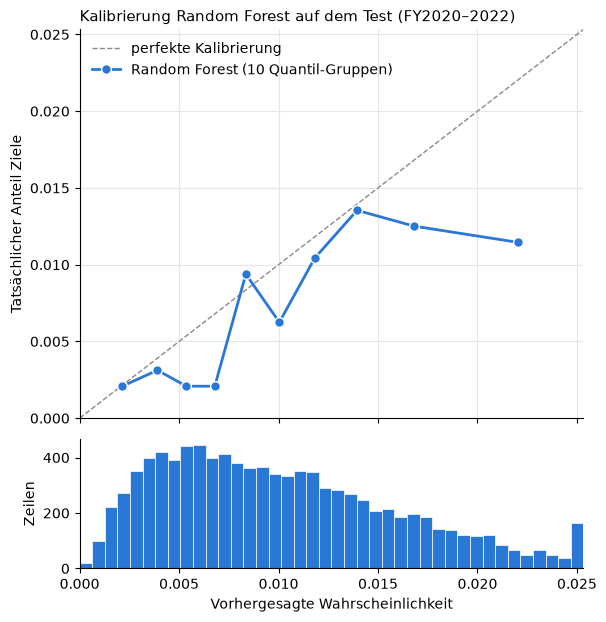

Vorhersagen oberhalb 0.025: 130 | Mittel vorhergesagt 1.012% | tatsächlich 0.729%


,Vorhersage_Mittel,Anteil_Ziele,Zeilen,Ziele
bin,,,,
0,0.0021,0.0021,960,2
1,0.0039,0.0031,960,3
2,0.0054,0.0021,959,2
3,0.0068,0.0021,960,2
4,0.0084,0.0094,959,9
5,0.0100,0.0062,960,6
6,0.0118,0.0104,959,10
7,0.0139,0.0135,960,13
8,0.0168,0.0125,959,12


In [8]:
BLUE, GRAY = "#2a78d6", "#8a8984"

def calibration_plot(p, title):
    d = pd.DataFrame({"p": p, "y": y})
    d["bin"] = pd.qcut(d["p"], 10, labels=False, duplicates="drop")
    cal = d.groupby("bin").agg(Vorhersage_Mittel=("p", "mean"), Anteil_Ziele=("y", "mean"), Zeilen=("y", "size"), Ziele=("y", "sum"))
    limit = max(cal["Vorhersage_Mittel"].max(), cal["Anteil_Ziele"].max()) * 1.15
    fig, (ax, axh) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08})
    ax.plot([0, limit], [0, limit], color=GRAY, linestyle="--", linewidth=1, label="perfekte Kalibrierung")
    ax.plot(cal["Vorhersage_Mittel"], cal["Anteil_Ziele"], color=BLUE, linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", label=f"{title} ({len(cal)} Quantil-Gruppen)")
    ax.set_xlim(0, limit); ax.set_ylim(0, limit)
    ax.set_ylabel("Tatsächlicher Anteil Ziele")
    ax.set_title(f"Kalibrierung {title} auf dem Test (FY2020–2022)", loc="left", fontsize=11)
    ax.legend(frameon=False, loc="upper left")
    ax.grid(color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    axh.hist(np.clip(p, 0, limit * 0.999), bins=40, range=(0, limit), color=BLUE, edgecolor="white", linewidth=0.5)
    axh.set_xlabel("Vorhergesagte Wahrscheinlichkeit"); axh.set_ylabel("Zeilen")
    axh.spines[["top", "right"]].set_visible(False)
    plt.show()
    print(f"Vorhersagen oberhalb {limit:.3f}: {(p > limit).sum()} | Mittel vorhergesagt {p.mean():.3%} | tatsächlich {y.mean():.3%}")
    return cal.round(4)

calibration_plot(te["p_rf"].to_numpy(), "Random Forest")

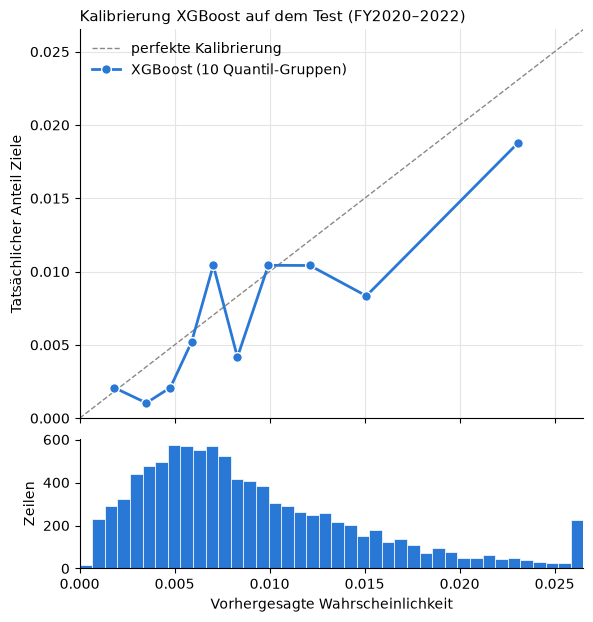

Vorhersagen oberhalb 0.027: 198 | Mittel vorhergesagt 0.915% | tatsächlich 0.729%


,Vorhersage_Mittel,Anteil_Ziele,Zeilen,Ziele
bin,,,,
0,0.0018,0.0021,960,2
1,0.0035,0.0010,960,1
2,0.0048,0.0021,959,2
3,0.0059,0.0052,960,5
4,0.0070,0.0104,959,10
5,0.0083,0.0042,960,4
6,0.0099,0.0104,959,10
7,0.0121,0.0104,960,10
8,0.0151,0.0083,959,8


In [9]:
calibration_plot(te["p_xgb"].to_numpy(), "XGBoost")

**Ergebnis:** Beide Baum-Modelle sind ohne Klassengewichte grob kalibriert, mit leichter Überschätzung wie beim Logit (Mittel: Random Forest 1,01 %, XGBoost 0,92 %, tatsächlich 0,73 %). Der **Random Forest ist in den obersten Gruppen zu sicher**: Er sagt dort 1,7–2,2 % voraus, tatsächlich sind es nur rund 1,2 %. XGBoost liegt in der obersten Gruppe näher (2,3 % gegenüber 1,9 %).

## 5. SHAP: Welche Variablen nutzen die Bäume, und in welche Richtung?

SHAP zerlegt jede einzelne Vorhersage in Beiträge der Variablen: Wie stark hat z. B. der freie Cashflow *dieser* Firma ihre Wahrscheinlichkeit nach oben oder unten geschoben? Der Mittelwert der Beträge (**mittleres |SHAP|**) zeigt, wie wichtig eine Variable insgesamt ist. Die **Richtung** bestimmen wir über die Rangkorrelation zwischen Variablenwert und SHAP-Wert: „+“ heißt, höhere Werte erhöhen die Vorhersage.

Berechnet auf dem ganzen Training (TreeExplainer). Achtung: Beim Random Forest sind SHAP-Werte in **Wahrscheinlichkeits**-Punkten, bei XGBoost in **Log-Odds** – die Größen sind daher nicht direkt vergleichbar, wohl aber die **Rangfolge**.

In [10]:
import shap

X_tr = tr[FEATURES]
shap_rf = shap.TreeExplainer(rf).shap_values(X_tr)
shap_rf = shap_rf[:, :, 1] if shap_rf.ndim == 3 else shap_rf          # Klasse 1 (Ziel)
shap_xgb = shap.TreeExplainer(xgb).shap_values(X_tr)
print("SHAP-Matrizen:", shap_rf.shape, shap_xgb.shape)

SHAP-Matrizen: (18058, 25) (18058, 25)


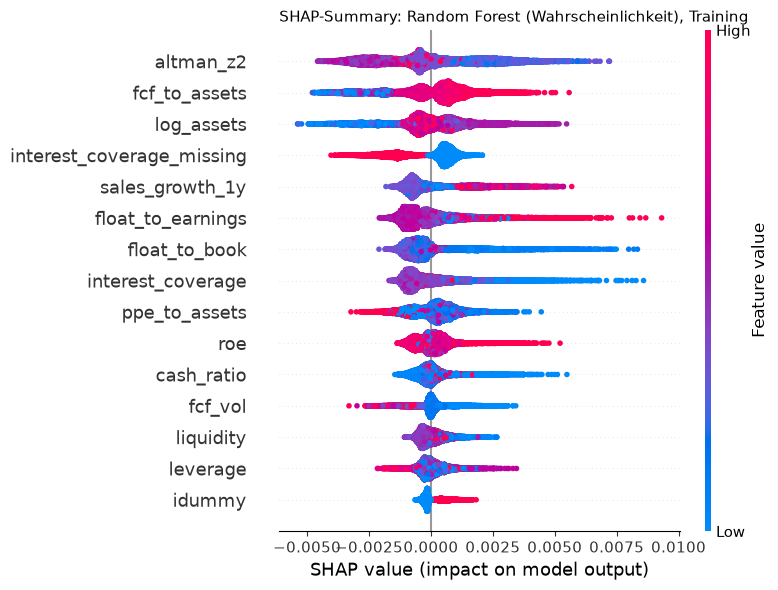

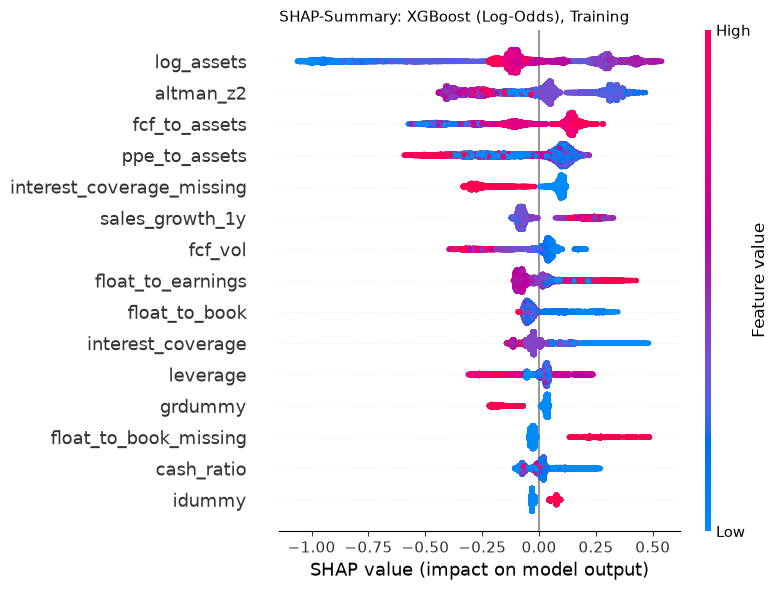

In [11]:
for values, title in [(shap_rf, "Random Forest (Wahrscheinlichkeit)"), (shap_xgb, "XGBoost (Log-Odds)")]:
    shap.summary_plot(values, X_tr, max_display=15, show=False, plot_size=(8, 6))
    plt.title(f"SHAP-Summary: {title}, Training", loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()

In [12]:
from scipy.stats import spearmanr

def shap_table(values):
    imp = np.abs(values).mean(axis=0)
    direction = []
    for j, f in enumerate(FEATURES):
        used = X_tr[f].nunique() > 1 and values[:, j].std() > 0     # Variable wird vom Modell überhaupt genutzt
        rho = spearmanr(X_tr[f], values[:, j]).statistic if used else np.nan
        direction.append("+" if rho > 0.1 else ("−" if rho < -0.1 else "uneinheitlich"))
    return pd.DataFrame({"mittleres |SHAP|": imp, "Richtung": direction}, index=FEATURES)

def logit_result(f):
    c, p = res_b.params[f], res_b.pvalues[f]
    if p >= 0.10:
        return "n.s."
    return f"{'+' if c > 0 else '−'} ({'sig.' if p < 0.05 else 'sig., 10 %'})"

t_rf, t_xgb = shap_table(shap_rf), shap_table(shap_xgb)
shap_cmp = pd.DataFrame({
    "RF: Rang": t_rf["mittleres |SHAP|"].rank(ascending=False).astype(int),
    "RF: mittl. |SHAP|": t_rf["mittleres |SHAP|"],
    "RF: Richtung": t_rf["Richtung"],
    "XGB: Rang": t_xgb["mittleres |SHAP|"].rank(ascending=False).astype(int),
    "XGB: mittl. |SHAP|": t_xgb["mittleres |SHAP|"],
    "XGB: Richtung": t_xgb["Richtung"],
    "Modell B (Logit)": [logit_result(f) for f in FEATURES],
}).sort_values("XGB: Rang")
shap_cmp.round({"RF: mittl. |SHAP|": 5, "XGB: mittl. |SHAP|": 4})

,RF: Rang,RF: mittl. |SHAP|,RF: Richtung,XGB: Rang,XGB: mittl. |SHAP|,XGB: Richtung,Modell B (Logit)
log_assets,3,0.00108,uneinheitlich,1,0.2870,−,n.s.
altman_z2,1,0.00167,−,2,0.2165,−,− (sig.)
fcf_to_assets,2,0.00116,+,3,0.1842,+,+ (sig.)
ppe_to_assets,9,0.00069,uneinheitlich,4,0.1565,+,"− (sig., 10 %)"
interest_coverage_missing,4,0.00095,−,5,0.1483,−,− (sig.)
sales_growth_1y,5,0.00093,+,6,0.1097,+,n.s.
fcf_vol,12,0.00043,−,7,0.0773,−,n.s.
float_to_earnings,6,0.00092,uneinheitlich,8,0.0741,−,n.s.
float_to_book,7,0.00091,−,9,0.0662,−,n.s.
interest_coverage,8,0.00086,−,10,0.0630,−,− (sig.)


Die Spalte „Richtung“ fasst nur eine **monotone** Tendenz zusammen. Im Summary-Plot sieht man bei `log_assets`, dass das Muster nicht monoton ist. Deshalb hier der mittlere SHAP-Wert je Zehntel der Firmengröße (Training):

In [13]:
size_decile = pd.qcut(X_tr["log_assets"], 10, labels=False) + 1
size_tab = pd.DataFrame({
    "Bilanzsumme Median (Mio. USD)": np.exp(X_tr["log_assets"]).groupby(size_decile).median() / 1e6,
    "RF: mittlerer SHAP": pd.Series(shap_rf[:, FEATURES.index("log_assets")]).groupby(size_decile).mean(),
    "XGB: mittlerer SHAP": pd.Series(shap_xgb[:, FEATURES.index("log_assets")]).groupby(size_decile).mean(),
    "Anteil Ziele": tr[Y].groupby(size_decile).mean(),
})
size_tab.index.name = "Größen-Zehntel"
size_tab.round({"Bilanzsumme Median (Mio. USD)": 0, "RF: mittlerer SHAP": 5, "XGB: mittlerer SHAP": 3, "Anteil Ziele": 4})

,Bilanzsumme Median (Mio. USD),RF: mittlerer SHAP,XGB: mittlerer SHAP,Anteil Ziele
Größen-Zehntel,,,,
1,11.0,-0.00272,-0.921,0.0000
2,102.0,-0.00069,-0.166,0.0100
3,228.0,0.00085,0.283,0.0083
4,416.0,0.00116,0.304,0.0122
5,748.0,0.00217,0.329,0.0217
6,1254.0,-0.00012,-0.054,0.0081
7,2074.0,-0.00048,-0.108,0.0089
8,3611.0,-0.00057,-0.117,0.0066
9,7166.0,-0.00025,-0.104,0.0100


**Ergebnis:**

- **Gleiches Profil wie das Logit:** Freier Cashflow (`fcf_to_assets`, +), Altman-Z (−), Zinsdeckung (−) und das Fehlen von Zinsaufwand (−) gehören in beiden Baum-Modellen zu den wichtigsten Variablen und haben dieselbe Richtung wie in Modell B.
- **Größe ist wichtig, aber nicht linear:** `log_assets` steht bei XGBoost auf Rang 1 und beim Random Forest auf Rang 3, obwohl sie im Logit nicht signifikant ist. Die Tabelle nach Größenzehnteln zeigt ein **umgekehrtes U**: Sehr kleine Firmen (Median 11 Mio. USD Bilanzsumme, kein einziges Ziel) senken die Vorhersage stark, mittelgroße (rund 200–750 Mio. USD) erhöhen sie, große senken sie leicht. Ein Logit mit einer linearen Größenvariable kann das nicht abbilden. Ein solcher umgekehrt U-förmiger Größeneffekt ist auch aus der Literatur bekannt (Tunyi 2019, siehe PROGRESS.md).
- **Unterschiede:** `ppe_to_assets` wirkt bei XGBoost eher *positiv*, im Logit schwach negativ. `grdummy` ist im Logit signifikant negativ, für die Bäume aber nachrangig (Rang 12 bzw. 22, Richtung ebenfalls −). Bei `cash_ratio` sind sich die beiden Baum-Modelle uneinig.

## Kernergebnisse

1. **Hilft Komplexität?** Nein: Random Forest (ROC-AUC 0,66) und XGBoost (0,68) sind im Test nicht besser als das Logit B (0,70); alle Differenzen haben Intervalle, die die Null einschließen.
2. Schon bei der Hyperparameter-Wahl gewinnen die vorsichtigen Einstellungen, und die Bäume schlagen eine reine Basisrate-Vorhersage nur knapp – bei 167 Zielen im Training ist zu wenig Information für komplexe Muster da.
3. **Sind die Wahrscheinlichkeiten kalibriert?** Grob ja, ohne Klassengewichte liegen sie nahe der Diagonale mit leichter Überschätzung; der Random Forest ist in den obersten Gruppen zu sicher.
4. **Sehen die Bäume dasselbe Profil wie das Logit?** Im Kern ja: Freier Cashflow (+), Distress-Nähe über Altman-Z (−), Zinslast und vorhandene Schulden prägen alle drei Modelle.
5. Der wichtigste Zusatzbefund der Bäume ist die **Firmengröße**: Ihr Effekt ist umgekehrt U-förmig (mittelgroße Firmen am ehesten Ziel), was ein lineares Logit übersieht – das erklärt, warum Größe dort nicht signifikant ist.